# Phase 5 — Modélisation et comparaison

**Objectif :** trouver le modèle qui classe le mieux les clients par risque de départ, **et** qui fournit des probabilités fiables, en comparant équitablement plusieurs familles de modèles.

**Plan**
1. Comparaison des modèles par défaut
2. Traitement du déséquilibre des classes
3. Optimisation des hyperparamètres (Optuna)
4. Choix du modèle final et sauvegarde

**Protocole commun** : même pipeline (Phase 4), mêmes plis de validation croisée (5 plis × 3 répétitions), **jeu d'entraînement uniquement**. Le jeu de test reste sous clé jusqu'à la Phase 6.

| Métrique | Rôle |
|---|---|
| **PR-AUC** | Métrique principale : qualité du classement des clients à risque (adaptée au déséquilibre) |
| ROC-AUC | Comparaison avec la littérature |
| **Brier** | Fiabilité des probabilités (plus bas = mieux). Essentiel : le gain attendu de la Phase 6 se calcule à partir de ces probabilités |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from churn.config import RANDOM_STATE
from churn.data import load_clean
from churn.features import split_data, build_pipeline
from churn.models import evaluate_cv, make_cv, results_table, corrected_paired_ttest
from churn.viz import set_style, save_fig, fmt_pct, BLUE, ORANGE, TEXT, TEXT_SECONDARY, GRID

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
X_train, X_test, y_train, y_test = split_data(load_clean())
cv = make_cv()
del X_test, y_test  # sous clé jusqu'à la Phase 6
print(f"Entraînement : {len(X_train)} clients, {fmt_pct(y_train.mean())} de churn")

Entraînement : 5634 clients, 26,5 % de churn


## 1. Comparaison des modèles par défaut

In [2]:
default_models = {
    "Dummy (taux moyen)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
}
results_default = {name: evaluate_cv(build_pipeline(m), X_train, y_train, cv=cv)
                   for name, m in default_models.items()}
table_default = results_table(results_default)
table_default.style.format({"pr_auc": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc": "{:.4f}",
                            "brier": "{:.4f}", "fit_time": "{:.2f} s"})

,pr_auc,pr_auc_std,roc_auc,brier,fit_time
Régression logistique,0.6747,0.0171,0.8512,0.1327,0.13 s
LightGBM,0.6480,0.0212,0.8360,0.1399,0.23 s
Random Forest,0.6198,0.0300,0.8224,0.1459,1.93 s
XGBoost,0.6180,0.0233,0.8203,0.1513,0.49 s
Dummy (taux moyen),0.2654,0.0001,0.5000,0.1949,0.17 s


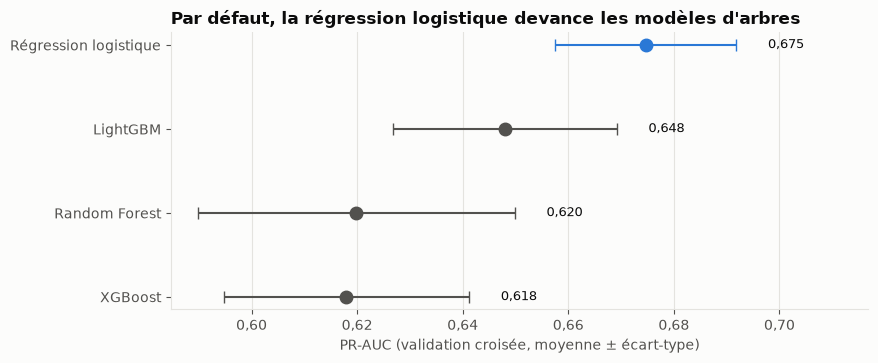

In [3]:
def plot_scores(table, title, filename, highlight=None):
    """Graphique en points : PR-AUC moyenne ± écart-type (axe tronqué → pas de barres)."""
    t = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(t) + 1.4))
    for i, (name, row) in enumerate(t.iterrows()):
        color = BLUE if name == highlight else TEXT_SECONDARY
        ax.errorbar(row["pr_auc"], i, xerr=row["pr_auc_std"], fmt="o", markersize=9,
                    color=color, ecolor=color, elinewidth=1.5, capsize=4)
        ax.text(row["pr_auc"] + row["pr_auc_std"] + 0.006, i, f"{row['pr_auc']:.3f}".replace(".", ","),
                va="center", fontsize=9, color=TEXT)
    ax.set_xlim(right=(t["pr_auc"] + t["pr_auc_std"]).max() + 0.025)
    ax.set_yticks(range(len(t)), t.index)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("PR-AUC (validation croisée, moyenne ± écart-type)")
    ax.set_title(title)
    save_fig(fig, filename)
    plt.show()

plot_scores(table_default.drop(index="Dummy (taux moyen)"),
            "Par défaut, la régression logistique devance les modèles d'arbres",
            "05_modeles_defaut.png", highlight="Régression logistique")

**Lecture :**
- Le **Dummy** obtient une PR-AUC de 0,265 (= le taux de churn) : c'est le plancher. Tous les modèles le dépassent très largement.
- La **régression logistique** arrive en tête (0,675), avec les **meilleures probabilités** (Brier le plus bas).
- Les modèles d'arbres par défaut sont **moins bons et plus instables** (écarts-types plus élevés). Pourquoi ? Vérifions s'ils sur-apprennent.

In [4]:
rows = []
for name in ["Régression logistique", "Random Forest", "XGBoost", "LightGBM"]:
    pipe = build_pipeline(default_models[name]).fit(X_train, y_train)
    train_score = average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1])
    rows.append({"modèle": name, "PR-AUC entraînement": train_score,
                 "PR-AUC validation croisée": results_default[name]["pr_auc"]})
overfit = pd.DataFrame(rows).set_index("modèle")
overfit["écart"] = overfit["PR-AUC entraînement"] - overfit["PR-AUC validation croisée"]
overfit.style.format("{:.3f}")

,PR-AUC entraînement,PR-AUC validation croisée,écart
modèle,,,
Régression logistique,0.679,0.675,0.004
Random Forest,1.000,0.620,0.380
XGBoost,0.935,0.618,0.317
LightGBM,0.841,0.648,0.193


**Diagnostic : sur-apprentissage.** Le Random Forest atteint une PR-AUC quasi parfaite (~1,0) sur les clients qu'il a vus à l'entraînement, mais bien moins sur des clients nouveaux. Il a **appris par cœur** (arbres profonds jusqu'à des feuilles d'un seul client). XGBoost et LightGBM sur-apprennent aussi, à un degré moindre. La régression logistique a un écart très faible : elle **généralise**.

C'est attendu avec les réglages par défaut, pensés pour de gros datasets. Sur 5 600 clients, il faut **contraindre** les arbres (profondeur, taille minimale des feuilles, taux d'apprentissage) : c'est l'objet de la section 3.

## 2. Traitement du déséquilibre des classes

Avec 26,5 % de churners, le réflexe habituel est de « rééquilibrer » :
- **`class_weight="balanced"`** : les erreurs sur les churners pèsent ~2,8 fois plus lourd dans l'apprentissage.
- **SMOTE** : création de churners **synthétiques** par interpolation, jusqu'à 50/50. Il est appliqué **à l'intérieur** de chaque pli (pipeline `imbalanced-learn`), sinon des clients synthétiques dérivés des clients de validation fuiraient dans l'entraînement.

On teste les deux sur la régression logistique et sur un LightGBM **contraint** (arbres peu profonds, apprentissage lent : réglages raisonnables avant l'optimisation de la section 3).

In [5]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

def with_smote(model):
    """Insère SMOTE entre le prétraitement et le modèle (appliqué uniquement aux plis d'entraînement)."""
    base = build_pipeline(model)
    return ImbPipeline(base.steps[:-1] + [("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])

lgbm_params = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, random_state=RANDOM_STATE, verbose=-1, n_jobs=1)
strategies = {
    ("Régression logistique", "Aucune"): build_pipeline(LogisticRegression(max_iter=2000)),
    ("Régression logistique", "class_weight"): build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    ("Régression logistique", "SMOTE"): with_smote(LogisticRegression(max_iter=2000)),
    ("LightGBM contraint", "Aucune"): build_pipeline(LGBMClassifier(**lgbm_params)),
    ("LightGBM contraint", "class_weight"): build_pipeline(LGBMClassifier(**lgbm_params, class_weight="balanced")),
    ("LightGBM contraint", "SMOTE"): with_smote(LGBMClassifier(**lgbm_params)),
}
imbalance = pd.DataFrame([
    {"modèle": m, "stratégie": s, **{k: v for k, v in evaluate_cv(est, X_train, y_train, cv=cv).items()
                                     if not k.endswith("_folds")}}
    for (m, s), est in strategies.items()
]).set_index(["modèle", "stratégie"])
imbalance[["pr_auc", "pr_auc_std", "roc_auc", "brier"]].style.format("{:.4f}")

**Résultat contre-intuitif :**
- **PR-AUC et ROC-AUC ne s'améliorent jamais** : au mieux inchangées (−0,001 à −0,002, dans le bruit), au pire en baisse (SMOTE sur LightGBM : −0,010). Rééquilibrer ne rend pas le modèle meilleur pour **classer** les clients.
- En revanche, le **score de Brier se dégrade** dans tous les cas (de 0,133 à 0,142–0,161) : les probabilités deviennent **fausses**.

Pourquoi ? Rééquilibrer revient à faire croire au modèle que 50 % des clients partent. Il **surestime donc systématiquement** le risque. La courbe de calibration le montre :

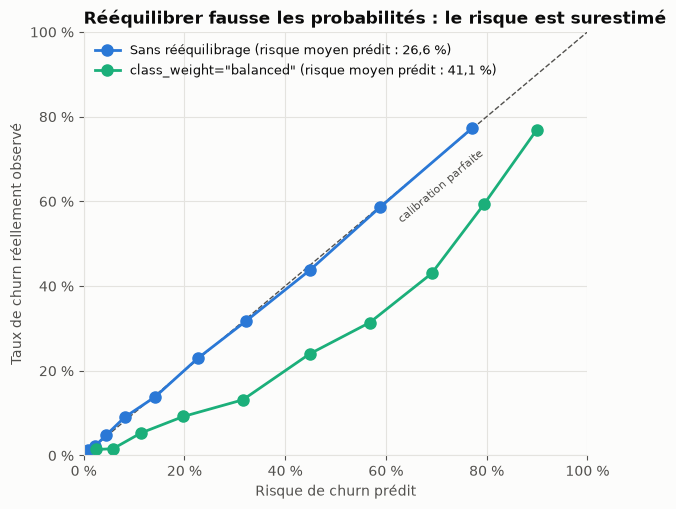

Taux de churn réel : 26,5 %


In [6]:
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from churn.viz import AQUA

cv_simple = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
calib = {}
for label, key, color in [("Sans rééquilibrage", ("Régression logistique", "Aucune"), BLUE),
                          ("class_weight=\"balanced\"", ("Régression logistique", "class_weight"), AQUA)]:
    proba = cross_val_predict(strategies[key], X_train, y_train, cv=cv_simple, method="predict_proba")[:, 1]
    frac_pos, mean_pred = calibration_curve(y_train, proba, n_bins=10, strategy="quantile")
    calib[label] = (mean_pred, frac_pos, color, proba.mean())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=TEXT_SECONDARY)
ax.text(0.62, 0.55, "calibration parfaite", rotation=40, fontsize=8, color=TEXT_SECONDARY)
for label, (x, y, color, mean_p) in calib.items():
    ax.plot(x, y, marker="o", markersize=8, lw=2, color=color,
            label=f"{label} (risque moyen prédit : {fmt_pct(mean_p)})")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Risque de churn prédit", ylabel="Taux de churn réellement observé")
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Rééquilibrer fausse les probabilités : le risque est surestimé")
save_fig(fig, "05_calibration_reequilibrage.png")
plt.show()
print(f"Taux de churn réel : {fmt_pct(y_train.mean())}")

**Lecture :** sans rééquilibrage, la courbe suit la diagonale : quand le modèle annonce 40 % de risque, environ 40 % de ces clients partent réellement. Avec `class_weight`, la courbe passe **nettement sous la diagonale** : le modèle annonce par exemple ~57 % de risque pour des clients qui ne partent qu'à ~31 %. Son risque moyen prédit (41 %) est **1,5 fois** le taux réel (26,5 %).

**Décision : aucun rééquilibrage.**
- Le rééquilibrage ne fait que **déplacer le seuil de décision** implicite, sans améliorer le classement.
- Or notre cas d'usage a besoin de **probabilités fiables** : le gain attendu d'une action (Phase 6) vaut `probabilité × valeur du client × taux de succès − coût`. Avec des probabilités surestimées, on surestimerait le gain de la campagne.
- Le déséquilibre sera traité **au bon endroit** : par le **choix du seuil de décision** optimisant le gain net (Phase 6).